# Lecture 23, Spatial downscaling

> From a coarse model grid to a fine grid: interpolation, BCSD, BCCA and BCSA

A climate model gives one rainfall number for a whole block of land, often 100 to 250 km wide. A catchment needs many numbers inside that block: the windward slope is wet and the valley behind it is dry. Spatial downscaling is the step from the few coarse numbers to many fine ones. We follow Chapter 9 of Lee and Singh (2019) in its own order: 9.1 interpolation, 9.2 BCSD, 9.3 BCCA, 9.4 BCSA and 9.5 a summary and comparison. The last three are named for what they do: *bias correction* of the model, followed by a spatial step.

By the end of this lecture you should be able to:

- fill in a fine-grid value from the four nearest coarse cells, by **bilinear** and **nearest-neighbour** interpolation (Section 9.1);
- do a **BCSD** step by hand: compare today with normal at coarse scale, spread that factor over the fine cells, and apply it to the fine normal (Section 9.2);
- explain in words what **BCCA** (a mix of similar past years) and **BCSA** (a random but realistic map) do (Sections 9.3 and 9.4);
- say which of the three gives smooth maps and which keep the extremes (Section 9.5).

All data are **synthetic**. The companion workbook `data/downscaling/lec23/lec23_worked_examples.xlsx` repeats the hand-solved example with live formulas.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas matplotlib scipy

## Words you need

- **Coarse and fine grid.** The coarse grid is the model's big blocks, the fine grid is the small cells we want. Here: 4 coarse cells and 16 fine cells.
- **Interpolation.** Estimating a value between known points from the points around it. Example: a point halfway between a 2 mm cell and a 4 mm cell gets about 3 mm.
- **Climatology.** The long-term average of a place. Example: 2, 4 and 3 mm/day in three Januaries give a climatology of 3 mm/day.
- **Bias factor (ratio).** Today's value divided by the climatology. Example: 3.0 mm today and 2.5 mm normal give 1.2, that is 20 % wetter than normal.
- **Analogue.** A past year whose coarse map looks like today's. We borrow its fine-scale map.
- **Regression weights.** Numbers that say how much of each past year to mix. Example: 0.7 of year A plus 0.3 of year B.
- **Correlation.** How closely two places rise and fall together: 1 means always together, 0 means unrelated.
- **Replicate.** One random fine-scale map made by the computer, with the same spatial behaviour as the observations.

## Notation

The symbols follow the book. Uppercase letters ($Y$, $X$) stand for unknown variables, lowercase ($y$, $x$) for known ones. Code names are ASCII: the subscripts come after an underscore in the book's order, `mu_` is $\mu$, `til` is a tilde.

| Book symbol | Meaning | Code and workbook |
|:--|:--|:--|
| $q$, $p$, $H$ | number of coarse cells, fine cells, observed years ($p > q$) | `q`, `p`, `H` |
| $a$, $b$, $z(a,b)$ | longitude, latitude, the interpolated value | `a`, `b`, `z` |
| $\mathbf{y}_{\text{obs}}$, $\mathbf{x}_{\text{obs}}$ | observed coarse ($q$ cells) and fine ($p$ cells) fields, one per year | `y_obs` ($H\times q$), `x_obs` ($H\times p$) |
| $\mathbf{y}_{\text{GCM}}$ | coarse GCM field to downscale (already bias corrected, as in the book's examples) | `y_GCM` |
| $\mathbf{X}_{\text{GCM}}$ | unknown fine field we want | `X_GCM` |
| $\mu_{y_{\text{obs}},i}$, $\mu_{x_{\text{obs}},j}$ | mean over the $H$ years of coarse cell $i$ and of fine cell $j$ (Eqs. 9.5, 9.7) | `mu_y_obs`, `mu_x_obs` |
| $R_i$, $R_j$ | ratio at coarse cell $i$ (Eq. 9.4) and its interpolation to fine cell $j$ | `R_i`, `R_j` |
| $\text{RMSE}_h$, $K$, $\mathbf{A}$ | distance of year $h$ to the target, number of analogues, regression vector (Eqs. 9.8, 9.9) | `rmse_h`, `K`, `A` |
| $\mathbf{y}_{\text{obs}}$, $\mathbf{x}_{\text{obs}}$ as matrices | $q\times(K+1)$ and $p\times(K+1)$ matrices with a first column of ones (the book reuses the symbols) | `y_mat`, `x_mat` |
| $F_{x_o}$, $F_{y_o}$, $\Phi^{-1}$ | fitted gamma CDFs of the fine and coarse observations, inverse standard normal CDF | `gamma.cdf`, `norm.ppf` |
| $\tilde x_{\text{obs},i}$, $\tilde y_{\text{GCM},j}$ | normal scores (Eqs. 9.12, 9.13) | `x_til_obs`, `y_til_GCM` |
| $\boldsymbol\rho$, $N_G$, $\mathbf{X}_n$ | correlation matrix of the fine scores, number of replicates, replicate $n$ (Eqs. 9.14, 9.15) | `rho`, `N_G`, `X_n` |

**Grid and order.** Coarse cells are $Y_1, Y_2$ (south, west to east) and $Y_3, Y_4$ (north). Fine cells $X_1,\dots,X_{16}$ run row by row from the south-west corner: $X_j$ has $j = 4(\text{row}-1)+\text{column}$. A coarse cell is 1 degree wide and a fine cell 0.5 degree. In the gamma distribution of Section 9.4, $\beta$ is the **scale** and $\alpha$ the shape, as in the book.

## 9.1 Mathematical background

### 9.1.1 Bilinear interpolation

**In plain words:** bilinear interpolation is a distance-weighted average of the four nearest coarse cells: the closer a coarse cell, the more it counts. Example: a fine point very close to a 4 mm cell and far from three 8 mm cells gets a value near 5 mm, not 6.

The book knows the value $z(a,b)$ at four corner points, $z(a_1,b_1)$, $z(a_1,b_2)$, $z(a_2,b_1)$, $z(a_2,b_2)$, where $a$ is the longitude and $b$ the latitude (here $z$ is rainfall), and wants it at the point $(a_p,b_p)$. First it finds the values at $(a_p,b_1)$ and $(a_p,b_2)$, that is, along the longitude on the southern and on the northern edge:

$$z(a_p,b_1)=\frac{a_2-a_p}{a_2-a_1}\,z(a_1,b_1)+\frac{a_p-a_1}{a_2-a_1}\,z(a_2,b_1) \qquad \text{(9.1)}$$

$$z(a_p,b_2)=\frac{a_2-a_p}{a_2-a_1}\,z(a_1,b_2)+\frac{a_p-a_1}{a_2-a_1}\,z(a_2,b_2) \qquad \text{(9.2)}$$

*Gloss:* each fraction is a weight; the weights of the two cells on an edge add to 1, and the nearer cell has the larger weight. Then it interpolates between these two edge values along the latitude:

$$z(a_p,b_p)=\frac{b_2-b_p}{b_2-b_1}\,z(a_p,b_1)+\frac{b_p-b_1}{b_2-b_1}\,z(a_p,b_2) \qquad \text{(9.3)}$$

The book also writes (9.3) as one matrix product, $z(a_p,b_p)=\dfrac{1}{(a_2-a_1)(b_2-b_1)}\,[\,a_2-a_p,\; a_p-a_1\,]\begin{bmatrix} z(a_1,b_1) & z(a_1,b_2)\\ z(a_2,b_1) & z(a_2,b_2)\end{bmatrix}\begin{bmatrix} b_2-b_p\\ b_p-b_1\end{bmatrix}$. The result always lies between the smallest and the largest corner value, so interpolation smooths and cannot make a new extreme.

*What this means for hydrology:* an interpolated rainfall map looks smooth and reasonable, but it will never show the wet ridge or the flood peak that lies inside one coarse cell.

### Worked example (by hand), in the style of Example 9.1

**Problem.** A $2\times2$ coarse grid has cell centres at $a_1=77.5$, $a_2=78.5$ (degrees E) and $b_1=29.5$, $b_2=30.5$ (degrees N). The model values are $Y_1=z(a_1,b_1)=3.0$, $Y_2=z(a_2,b_1)=5.0$, $Y_3=z(a_1,b_2)=4.5$, $Y_4=z(a_2,b_2)=2.0$ mm/day. Find the value at the fine cell $X_7$ with centre $(a_p,b_p)=(78.25,\,29.75)$.

- *Fractions first, they say how far across the box the point is.* Along $a$: $(a_2-a_p)/(a_2-a_1)=(78.5-78.25)/1.0=0.25$ and $(a_p-a_1)/(a_2-a_1)=0.75$. Along $b$: $(b_2-b_p)/(b_2-b_1)=(30.5-29.75)/1.0=0.75$ and $(b_p-b_1)/(b_2-b_1)=0.25$. The point lies near the eastern side and the southern side.
- *Eq. 9.1, the southern edge, the eastern cell counting more:* $z(a_p,b_1)=0.25\times3.0+0.75\times5.0=0.75+3.75=4.50$.
- *Eq. 9.2, the northern edge in the same way:* $z(a_p,b_2)=0.25\times4.5+0.75\times2.0=1.125+1.50=2.625$.
- *Eq. 9.3, between the two edges, the southern one counting more:* $z(a_p,b_p)=0.75\times4.50+0.25\times2.625=3.375+0.656=4.031$ mm/day.
- *Check:* the weight of each cell is the product of its two fractions, $0.1875$, $0.5625$, $0.0625$, $0.1875$. They add to 1, and $0.1875\times3.0+0.5625\times5.0+0.0625\times4.5+0.1875\times2.0=4.031$.

**Answer.** $z(a_p,b_p)\approx4.03$ mm/day, a blend dominated by the eastern southern cell $Y_2$.

### 9.1.2 Nearest-neighbour interpolation

The point simply takes the value of the closest coarse cell. For the same point $X_7$ the closest cell centre is $(a_2,b_1)$, so $z(a_p,b_p)=Y_2=5.0$ mm/day. The map is blocky, but no new values appear.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gamma, norm

# grid: a = longitude, b = latitude; row 0 is the southern row, column 0 the western column
a_c, b_c = np.array([77.5, 78.5]), np.array([29.5, 30.5])                                   # coarse centres, q = 4
a_f, b_f = np.array([77.25, 77.75, 78.25, 78.75]), np.array([29.25, 29.75, 30.25, 30.75])   # fine centres, p = 16

def bilinear_point(a_p, b_p, z):
    # Eq. 9.3 in matrix form; z[row = b index, column = a index], so z.T = [[z11, z12], [z21, z22]]
    a1, a2 = a_c; b1, b2 = b_c
    a_p, b_p = np.clip(a_p, a1, a2), np.clip(b_p, b1, b2)           # outside the coarse centres: nearest value
    wa = np.array([a2 - a_p, a_p - a1]) / (a2 - a1)
    wb = np.array([b2 - b_p, b_p - b1]) / (b2 - b1)
    return wa @ z.T @ wb

def interp_grid(z):                                                  # 2 x 2 coarse -> 4 x 4 fine, bilinear
    return np.array([[bilinear_point(a, b, z) for a in a_f] for b in b_f])

def nearest_grid(z):                                                 # each coarse value copied to its 2 x 2 fine cells
    return np.kron(z, np.ones((2, 2)))

# ---- the hand-solved example (fine cell X7)
y_GCM_h = np.array([3.0, 5.0, 4.5, 2.0])                             # Y1..Y4
a_p, b_p = 78.25, 29.75
z = y_GCM_h.reshape(2, 2)
print("bilinear z(a_p, b_p) =", round(bilinear_point(a_p, b_p, z), 5), "  nearest neighbour =", z[0, 1])

bilinear z(a_p, b_p) = 4.03125   nearest neighbour = 5.0


## 9.2 Bias correction and spatial downscaling (BCSD)

**In plain words:** The coarse model tells us how much wetter or drier than normal a place is. The fine observations tell us what normal looks like in detail. BCSD joins the two. Example: the model says a coarse cell is 20 % wetter than normal. A ridge cell that normally gets 6 mm/day then gets 7.2 mm/day, and a valley cell that normally gets 2 mm/day gets 2.4 mm/day.

BCSD uses observed data at coarse and fine resolution and the coarse GCM field. First the coarse GCM output is **bias corrected** by quantile mapping against the observed coarse data (Lecture 18); the book's worked example skips this step and so do we, taking $\mathbf{y}_{\text{GCM}}$ (the coarse model values) as already corrected. The **spatial** step has three parts, for $q$ coarse cells and $p$ fine cells:

1. **Ratio** (bias factor) at each coarse cell: the model value divided by the observed mean $\mu_{y_{\text{obs}},i}$ over the $H$ years:

   $$R_i=\frac{y_{\text{GCM},i}}{\mu_{y_{\text{obs}},i}},\quad i=1,\dots,q, \qquad \mu_{y_{\text{obs}},i}=\frac1H\sum_{h=1}^{H}y_{\text{obs},i}^{\,h} \qquad \text{(9.4, 9.5)}$$

2. **Interpolate** the ratios $R_i$ to the fine cells with a rule of Section 9.1. The result is $R_j$, one ratio per fine cell $j=1,\dots,p$.
3. **Rescale**: multiply each fine ratio by the observed fine mean $\mu_{x_{\text{obs}},j}$ of that cell:

   $$X_{\text{GCM},j}=R_j\,\mu_{x_{\text{obs}},j},\quad j=1,\dots,p, \qquad \mu_{x_{\text{obs}},j}=\frac1H\sum_{h=1}^{H}x_{\text{obs},j}^{\,h} \qquad \text{(9.6, 9.7)}$$

**Why a ratio and not the rainfall itself?** Interpolating the rainfall would blur the ridge away. A ratio stays close to 1 everywhere, so smoothing it does little harm, and the sharp pattern comes from the fine mean, which is never smoothed.

*What this means for hydrology:* BCSD keeps the observed wet and dry pattern of a catchment and only scales it up or down with the model's change, which is why it is so common in climate-impact studies.

### Worked example (by hand), in the style of Example 9.2

**Problem.** Same grid as above. The bias-corrected model values are $y_{\text{GCM}}=(Y_1,Y_2,Y_3,Y_4)=(3.0,\,5.0,\,4.5,\,2.0)$ mm/day, the observed coarse means (over the $H$ years) are $\mu_{y_{\text{obs}}}=(2.5,\,4.0,\,3.0,\,2.5)$ mm/day, and the fine cell $X_7$ (centre $(78.25,\,29.75)$) has an observed mean $\mu_{x_{\text{obs}},7}=3.6$ mm/day. Find $X_{\text{GCM},7}$.

1. *Ratios at the coarse cells (Eq. 9.4); they say how today compares with normal:* $R_1=3.0/2.5=1.20$, $R_2=5.0/4.0=1.25$, $R_3=4.5/3.0=1.50$, $R_4=2.0/2.5=0.80$.
2. *Interpolate the ratios to $X_7$; the fine cell lies between the coarse cells, so it gets a blend of their ratios.* The fractions are those of Example 9.1: $R(a_p,b_1)=0.25\times1.20+0.75\times1.25=0.30+0.9375=1.2375$, $R(a_p,b_2)=0.25\times1.50+0.75\times0.80=0.375+0.600=0.975$, so $R_7=0.75\times1.2375+0.25\times0.975=0.9281+0.2438=1.1719$.
3. *Multiply by the observed fine mean (Eq. 9.6); this puts the detailed local normal back:* $X_{\text{GCM},7}=R_7\,\mu_{x_{\text{obs}},7}=1.1719\times3.6=4.219$ mm/day.

**Answer.** BCSD gives 4.22 mm/day at $X_7$, plain interpolation 4.03 mm/day. The period is about 17 % wetter than normal there, and BCSD applies that to the local normal of 3.6 mm/day, which is higher than the smooth value 3.375 mm/day obtained by interpolating the coarse means. BCSD thus keeps the cell wetter than its surroundings.

The next cell checks the numbers and gives all 16 fine cells (sheets `Bilinear` and `BCSD`).

In [3]:
def bcsd(y_GCM, mu_y_obs, mu_x_obs):
    R_i = y_GCM / mu_y_obs                                                                  # Step 1, Eq. 9.4
    R_j = np.array([interp_grid(r.reshape(2, 2)).ravel() for r in np.atleast_2d(R_i)])      # Step 2, bilinear
    return R_j * mu_x_obs                                                                   # Step 3, Eq. 9.6

mu_y_h   = np.array([2.5, 4.0, 3.0, 2.5])
mu_x_h   = np.array([[1.6, 3.4, 4.2, 3.8], [1.9, 3.1, 3.6, 4.4], [2.4, 3.8, 2.1, 2.5], [2.2, 3.6, 1.9, 3.5]]).ravel()
R_i = y_GCM_h / mu_y_h
R_j = interp_grid(R_i.reshape(2, 2))
X_GCM_h = R_j.ravel() * mu_x_h
print("R_i =", R_i, "  R_7 =", round(R_j[1, 2], 6), "  X_GCM,7 =", round(X_GCM_h[6], 5))
print("plain interpolation of mu_y_obs at X7:", round(bilinear_point(a_p, b_p, mu_y_h.reshape(2, 2)), 4))
print("all 16 fine cells, X_GCM (rows from the south):")
print(np.round(X_GCM_h.reshape(4, 4), 3))

R_i = [1.2  1.25 1.5  0.8 ]   R_7 = 1.171875   X_GCM,7 = 4.21875
plain interpolation of mu_y_obs at X7: 3.375
all 16 fine cells, X_GCM (rows from the south):
[[1.92  4.122 5.198 4.75 ]
 [2.422 3.846 4.219 5.005]
 [3.42  4.928 2.185 2.281]
 [3.3   4.77  1.852 2.8  ]]


### Example 9.2 continued: a data set for BCSD, BCCA and BCSA

The book uses one data set for Examples 9.2 to 9.4, and so do we. We need many years of fine data. The synthetic region has a $4\times4$ fine grid ($p=16$) inside a $2\times2$ coarse grid ($q=4$), with a wetter east and a wetter second column. We generate spatially linked January mean rainfall (mm/day) for $H=30$ observed years and 5 target years. The observed coarse value of a cell is the average of its four fine cells. For the target years we use the coarse averages as the (bias-corrected) model field $\mathbf{y}_{\text{GCM}}$, so the true fine field is known and we can see how well each method recovers it. A real model does not match observed years one to one; the book's own examples also check against observed years.

Averaging to the coarse grid removes the detail: the fine mean map varies from about 1 to 3.5 mm/day across its 16 cells, the coarse map has only four values. BCSD puts the detail back through $\mu_{x_{\text{obs}},j}$.

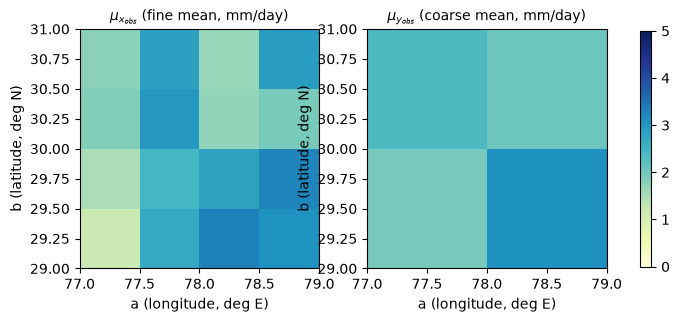

H = 30 years, q = 4 coarse cells, p = 16 fine cells, T = 5 target years


In [4]:
BASE = "data/downscaling/lec23/"
RAW = "https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/data/downscaling/lec23/"
def load(name):
    # header-less CSV matrix from the repository folder, or from GitHub (e.g. on Colab)
    try:
        return pd.read_csv(BASE + name, header=None).to_numpy(float)
    except FileNotFoundError:
        return pd.read_csv(RAW + name, header=None).to_numpy(float)

def to_coarse(x):                                                    # (n, 16) fine -> (n, 4) coarse: mean of each 2 x 2 block
    return x.reshape(-1, 2, 2, 2, 2).mean(axis=(2, 4)).reshape(len(x), 4)

x_obs = load("fine_obs.csv")                  # H x p, observed years
x_target = load("fine_target.csv")            # T x p, true fine fields of the 5 target years
y_obs, y_GCM = to_coarse(x_obs), to_coarse(x_target)
H, p = x_obs.shape; q = y_obs.shape[1]; T = len(y_GCM)
mu_y_obs, mu_x_obs = y_obs.mean(0), x_obs.mean(0)                    # Eqs. 9.5, 9.7
t = 4                                                                # the wettest target year, used in the maps

ext = [77, 79, 29, 31]
def show(ax, f, title, vmax):
    n = int(np.sqrt(f.size))
    im = ax.imshow(f.reshape(n, n), origin="lower", extent=ext, cmap="YlGnBu", vmin=0, vmax=vmax)
    ax.set_title(title, fontsize=10); ax.set_xlabel("a (longitude, deg E)"); ax.set_ylabel("b (latitude, deg N)")
    return im

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
im = show(axes[0], mu_x_obs, r"$\mu_{x_{obs}}$ (fine mean, mm/day)", 5)
show(axes[1], mu_y_obs, r"$\mu_{y_{obs}}$ (coarse mean, mm/day)", 5)
fig.colorbar(im, ax=axes, shrink=0.85); plt.show()
print(f"H = {H} years, q = {q} coarse cells, p = {p} fine cells, T = {T} target years")

In [5]:
X_nearest = np.array([nearest_grid(y.reshape(2, 2)).ravel() for y in y_GCM])       # Section 9.1, no bias correction needed here
X_bilinear = np.array([interp_grid(y.reshape(2, 2)).ravel() for y in y_GCM])
X_bcsd = bcsd(y_GCM, mu_y_obs, mu_x_obs)                                            # Eqs. 9.4 to 9.7
R_i = y_GCM[t] / mu_y_obs
print("target year", t + 1, ": y_GCM =", np.round(y_GCM[t], 2), " R_i =", np.round(R_i, 2))
print("BCSD fine field (rows from the south):"); print(np.round(X_bcsd[t].reshape(4, 4), 2))

target year 5 : y_GCM = [4.82 9.09 5.49 5.73]  R_i = [2.45 2.91 2.31 2.78]
BCSD fine field (rows from the south):
[[2.91 6.96 9.33 8.98]
 [3.63 6.25 7.78 9.37]
 [4.39 7.37 4.63 5.47]
 [4.08 6.96 4.42 8.12]]


## 9.3 Bias correction and constructed analogues (BCCA)

**In plain words:** look through the past years for the ones whose coarse map looks most like the target map. Mix their fine maps so that the mixed coarse map matches the target. Example: if the target looks 70 % like year A and 30 % like year B, the fine map is 0.7 times the fine map of A plus 0.3 times that of B. The fine pattern is then made of patterns that really happened.

The book states three conditions: (i) the new coarse pattern $\mathbf{y}_{\text{GCM}}$ is known and the fine pattern is unknown; (ii) a subset of a historical library of patterns is used, chosen for similarity of the coarse patterns; (iii) a linear combination of the fine patterns gives a least-squares fit. Steps, for $q$ coarse cells, $p$ fine cells and $H$ observed years:

1. **Find the closest patterns.** For each observed year $h=1,\dots,H$ compute the RMSE between the target and that year's coarse field (the square root of the mean squared difference; example: target 2 and 4, year $h$ has 3 and 3, differences 1 and 1, RMSE $=1$; small means similar):

   $$\text{RMSE}_h=\sqrt{\frac1q\sum_{i=1}^{q}\bigl(y_{\text{GCM},i}-y_{\text{obs},i}^{\,h}\bigr)^2} \qquad \text{(9.8)}$$

2. **Select the $K$ years** with the smallest $\text{RMSE}_h$, call them $(1),\dots,(K)$, and collect their coarse fields. The book suggests $K=30$ for big grids; we have only $q=4$ coarse cells and use $K=2$, as the book's example does.
3. **Fit the mixing weights.** Multiple linear regression (least squares) of the target on the selected coarse fields, with an intercept, that is, a constant weight $A_0$ for a column of ones. The weights are the vector $\mathbf{A}$ with $K+1$ entries; $\mathbf{y}_{\text{obs}}$ here is the $q\times(K+1)$ matrix whose first column is ones and whose other columns are the selected coarse fields (code `y_mat`):

   $$\mathbf{A}=\bigl(\mathbf y_{\text{obs}}^{T}\mathbf y_{\text{obs}}\bigr)^{-1}\mathbf y_{\text{obs}}^{T}\,\mathbf y_{\text{GCM}} \qquad \text{(9.9)}$$

4. **Apply the weights to the fine fields** of the same years. $\mathbf{x}_{\text{obs}}$ is the $p\times(K+1)$ matrix with a first column of ones and the selected fine fields (code `x_mat`):

   $$\mathbf{X}_{\text{GCM}}=\mathbf{x}_{\text{obs}}\,\mathbf{A} \qquad \text{(9.10, 9.11)}$$

Repeat Steps 1 to 4 for every target year. The weights are not forced to be positive, so a fine cell can come out slightly below zero. (Some codes add a ridge term to Step 3 for stability; the book's version does not.)

*What this means for hydrology:* BCCA gives fine rainfall maps that look like real storms, but it needs a long library of fine maps, and an occasional negative rainfall has to be set to zero.

In [6]:
def bcca(y_GCM_t, y_obs, x_obs, K):
    rmse_h = np.sqrt(((y_GCM_t - y_obs) ** 2).mean(1))                           # Step 1, Eq. 9.8
    sel = np.argsort(rmse_h)[:K]                                                 # Step 2: the K closest years, (1), ..., (K)
    y_mat = np.column_stack([np.ones(len(y_GCM_t))] + [y_obs[h] for h in sel])   # q x (K+1)
    x_mat = np.column_stack([np.ones(x_obs.shape[1])] + [x_obs[h] for h in sel]) # p x (K+1)
    A = np.linalg.solve(y_mat.T @ y_mat, y_mat.T @ y_GCM_t)                      # Step 3, Eq. 9.9
    return x_mat @ A, A, sel, rmse_h                                             # Step 4, Eq. 9.10

K = 2
X_bcca = np.array([bcca(y, y_obs, x_obs, K)[0] for y in y_GCM])
X_t, A, sel, rmse_h = bcca(y_GCM[t], y_obs, x_obs, K)
print(f"target year {t+1}: closest years h = {sel + 1}, RMSE_h = {np.round(rmse_h[sel], 3)}, A = {np.round(A, 3)}")
print("lowest value of the BCCA fields over the 5 target years: %.2f mm/day" % X_bcca.min())

# same computation as the sheet BCCA: the first 8 years as library and target year 1
X_s, A_s, sel_s, _ = bcca(y_GCM[0], y_obs[:8], x_obs[:8], K)
print("sheet BCCA: h =", sel_s + 1, " A =", np.round(A_s, 4), " X_GCM,1..4 =", np.round(X_s[:4], 3))

target year 5: closest years h = [14 25], RMSE_h = [1.788 2.064], A = [2.598 0.802 0.004]
lowest value of the BCCA fields over the 5 target years: -0.55 mm/day
sheet BCCA: h = [1 4]  A = [ 4.889 -1.669  0.305]  X_GCM,1..4 = [1.873 0.163 1.11  3.605]


## 9.4 Bias correction and stochastic analogue (BCSA)

**In plain words:** instead of mixing past maps, let the computer draw many random fine maps that behave like the observations (wet cells tend to be wet together), and keep the one whose overall average fits the target. Example: draw 10,000 random maps and keep the one whose domain average is closest to the average the model suggests.

The book (after Hwang and Graham, 2013) states three conditions: (i) quantile mapping turns the observed fine data into a standard normal variable, cell by cell (this is the bias correction); (ii) spatially correlated replicates are generated and transformed back to the observed distributions; (iii) the replicate whose spatial mean is closest to the spatial mean of the target is selected. Steps:

1. **Normal scores.** Fit a distribution to each fine cell of $x_{\text{obs}}$ (CDF $F_{x_o}$) and to each coarse cell of $y_{\text{obs}}$ (CDF $F_{y_o}$); the book uses the gamma distribution, a skewed shape typical for rainfall, with shape $\alpha$ and scale $\beta$ from the mean $\mu$ and standard deviation $\sigma$ as $\beta=\sigma^2/\mu$, $\alpha=\mu/\beta$ (example: $\mu=2.4$, $\sigma=1.2$ give $\beta=0.6$, $\alpha=4$). Then replace every value by its *normal score*, the value with the same probability on the standard normal curve ($\Phi^{-1}$ is its inverse CDF; an average value gets a score near 0, a very wet one a large positive score):

   $$\tilde x_{\text{obs},i}=\Phi^{-1}\bigl(F_{x_o}(x_{\text{obs},i})\bigr),\ i=1,\dots,p \quad \text{(9.12)}\qquad \tilde y_{\text{GCM},j}=\Phi^{-1}\bigl(F_{y_o}(y_{\text{GCM},j})\bigr),\ j=1,\dots,q \quad \text{(9.13)}$$

   $F_{y_o}$ must be fitted to the **observed** coarse data $y_{\text{obs},j}$, not to $y_{\text{GCM},j}$.
2. **Correlation** between the normal scores of every pair of fine cells (1 means they rise and fall together, 0 unrelated); the result is a $p\times p$ matrix:

   $$\rho_{ij}=\operatorname{corr}\bigl(\tilde x_{\text{obs},i},\tilde x_{\text{obs},j}\bigr),\quad i,j=1,\dots,p \qquad \text{(9.14)}$$

3. **Simulate $N_G$ replicates** (random maps of scores) with zero mean and exactly this correlation, from the multivariate normal distribution. The book recommends at least $10^4$ (its hand example uses 30):

   $$\mathbf X_n\sim\text{MVN}(\mathbf 0,\boldsymbol\rho),\quad n=1,\dots,N_G \qquad \text{(9.15)}$$

4. **Select** the replicate whose spatial mean $\overline{\mathbf X_n}$ is closest to the spatial mean of the target scores:

   $$n^{*}=\arg\min_{n}\bigl|\,\overline{\mathbf X_n}-\overline{\tilde{\mathbf y}_{\text{GCM}}}\,\bigr| \qquad \text{(9.16)}$$

5. **Back-transform** the chosen replicate to rainfall, cell by cell: $X_{\text{GCM},i}=F_{x_o,i}^{-1}\bigl(\Phi(\tilde X_{\text{GCM},i})\bigr)$, $i=1,\dots,p$.
6. **Repeat** Steps 4 and 5 for every target year.

The field looks like real rainfall, but the selection uses only one number, the domain mean, so *where* the wet cells lie is largely luck.

*What this means for hydrology:* BCSA keeps realistic variability and peaks, so it suits studies where extremes matter; but one map is one possibility among many.

In [7]:
def gamma_mom(x):                                    # method of moments: beta = sigma^2 / mu (scale), alpha = mu / beta
    mu, sd = x.mean(0), x.std(0, ddof=1)
    beta = sd ** 2 / mu
    return mu / beta, beta

alpha_y, beta_y = gamma_mom(y_obs)                   # coarse cells
alpha_x, beta_x = gamma_mom(x_obs)                   # fine cells
x_til_obs = norm.ppf(gamma.cdf(x_obs, alpha_x, scale=beta_x))        # Step 1, Eq. 9.12
y_til_GCM = norm.ppf(gamma.cdf(y_GCM, alpha_y, scale=beta_y))        # Step 1, Eq. 9.13 (F_yo fitted to y_obs)
rho = np.corrcoef(x_til_obs.T)                                       # Step 2, Eq. 9.14

rng = np.random.default_rng(23)
N_G = 10_000
X_bcsa = np.empty((T, p))
for k in range(T):                                                   # Step 6: every target year
    X_n = rng.multivariate_normal(np.zeros(p), rho, size=N_G)        # Step 3, Eq. 9.15
    n_star = np.argmin(np.abs(X_n.mean(1) - y_til_GCM[k].mean()))    # Step 4, Eq. 9.16
    X_bcsa[k] = gamma.ppf(norm.cdf(X_n[n_star]), alpha_x, scale=beta_x)   # Step 5, back-transform
    if k == t:
        print(f"target year {t+1}: mean score of y_GCM {y_til_GCM[k].mean():.3f}, selected replicate {n_star} with mean {X_n[n_star].mean():.3f}")
print("BCSA fine field, target year", t + 1, "(rows from the south):"); print(np.round(X_bcsa[t].reshape(4, 4), 2))

target year 5: mean score of y_GCM 2.287, selected replicate 636 with mean 2.289
BCSA fine field, target year 5 (rows from the south):
[[ 2.61  9.28 11.44 10.74]
 [ 3.26  6.38  9.13  9.71]
 [ 5.38 12.05  6.22  3.48]
 [ 5.98  7.3   4.26  6.75]]


## 9.5 Summary and comparison

| | **BCSD** | **BCCA** | **BCSA** |
|:--|:--|:--|:--|
| **Spatial information from** | interpolated ratio times the fine mean | least-squares blend of $K$ real fine fields | correlated random replicate chosen by the domain mean |
| **Character of the field** | smooth | rougher, with real patterns | rough, realistic variability |
| **Skill for the particular year** | best of the three | in between | low: the pattern is largely random |
| **Extremes** | tend to be damped by the smoothing | better preserved; coefficients can give small negatives | preserved |
| **Needs** | fine mean and coarse observations | library of observed fine fields | fine and coarse observations, correlation matrix, many replicates |

The figure shows one target year for all methods, including the plain interpolations of Section 9.1.

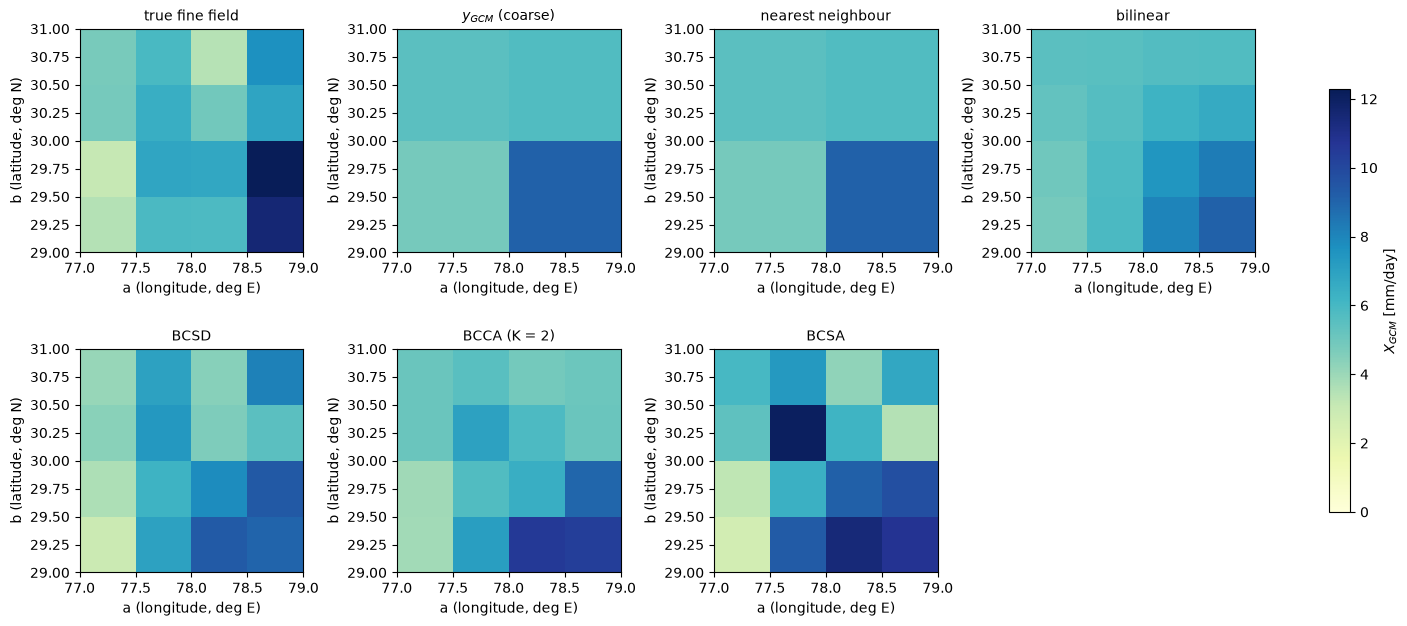

domain maximum (mm/day): {'true fine field': 12.28, 'nearest neighbour': 9.09, 'bilinear': 9.09, 'BCSD': 9.37, 'BCCA (K = 2)': 10.53, 'BCSA': 12.05}


In [8]:
fields = [("true fine field", x_target[t]), (r"$y_{GCM}$ (coarse)", np.kron(y_GCM[t].reshape(2, 2), np.ones((2, 2)))),
          ("nearest neighbour", X_nearest[t]), ("bilinear", X_bilinear[t]), ("BCSD", X_bcsd[t]),
          (f"BCCA (K = {K})", X_bcca[t]), ("BCSA", X_bcsa[t])]
vmax = max(f.max() for _, f in fields)
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4), constrained_layout=True)
for ax, (title, f) in zip(axes.ravel(), fields):
    im = show(ax, f, title, vmax)
axes.ravel()[-1].axis("off")
fig.colorbar(im, ax=axes, shrink=0.7, label=r"$X_{GCM}$ [mm/day]")
plt.show()
print("domain maximum (mm/day):", {n.replace("$", ""): round(float(f.max()), 2) for n, f in fields[:1] + fields[2:]})

In this synthetic year the BCSD map is the smoothest and its maximum is below the true one. BCCA and BCSA reach larger values, as the chapter says of rough methods. BCSA gets the overall level right through the domain mean, but where the wet cells sit is partly luck. The details change with the random numbers; Section 9.5 of the book makes the same points for a real Florida example.

*What this means for hydrology:* use BCSD for long-term water balance (means), and BCCA or BCSA (preferably several maps) when peak rainfall or the spread of wet cells matters.

## Summary

- Spatial downscaling turns a few coarse cells into many fine cells; the model bias is removed first (Lecture 18).
- **Bilinear interpolation** is a distance-weighted average of four coarse cells (Eqs. 9.1 to 9.3). It is smooth and adds no information. Nearest neighbour copies the closest cell.
- **BCSD**: today-to-normal ratio $R_i$ at coarse scale, interpolate it to $R_j$, multiply by the fine mean $\mu_{x_{\text{obs}},j}$ (Eqs. 9.4 to 9.7).
- **BCCA**: mix the fine maps of the $K$ most similar past years with least-squares weights and an intercept (Eqs. 9.8 to 9.11).
- **BCSA**: random correlated maps made from normal scores; keep the one whose mean fits the target (Eqs. 9.12 to 9.16).
- BCSD is smoothest and closest to the year; BCCA and BCSA are rougher and keep extremes.

## Check your understanding

1. A fine point lies exactly in the middle of four coarse cells with values 4, 8, 12 and 20 mm/day. Use the rule of Section 9.1: what are the four weights and the interpolated value? Could the value be 22 mm/day?
2. In the hand example of Section 9.2 the coarse cell $Y_4$ has $y_{\text{GCM}}=2.0$ and $\mu_{y_{\text{obs}}}=2.5$. What is its ratio $R_4$, and what does it say? A fine cell inside $Y_4$ has a fine mean of 3.5 mm/day and (to keep it simple) takes the ratio $R_4$: what does BCSD give?
3. From the comparison table: which method would you choose to study the largest daily rainfall at a catchment cell, and what should you not trust about the result for one particular year?

## Try it yourself

- Change `K` in `bcca` (1, 2, 3) and watch the weights $\mathbf{A}$ and the lowest value of the fields.
- Set `N_G = 30`, as in the book's hand example, and rerun BCSA. How much does the map change?
- Regenerate the data with `make_lec23_data.py` (another seed) and compare the maps again.

```{note} Where this lecture differs from the book
- Eqs. 9.12 and 9.13: the text mixes "fine" and "coarse". We read them consistently: $\tilde x_{\text{obs},i}$ uses the fine CDF $F_{x_o}$; $\tilde y_{\text{GCM},j}$ is the transform of the **coarse** $y_{\text{GCM},j}$ with $F_{y_o}$ fitted to $y_{\text{obs},j}$.
- Example 9.2 weights the bilinear interpolation by Haversine distance in km. On a regular grid this is inconsistent with Eqs. 9.1 to 9.3, which use coordinate differences in degrees; we use the equations.
- Eq. 9.9: the text calls the entries of $\mathbf y_{\text{obs}}$ "selected GCM outputs"; they are the selected **observed** coarse fields. The book reuses $\mathbf y_{\text{obs}}$, $\mathbf x_{\text{obs}}$ for the matrices with a column of ones (`y_mat`, `x_mat`).
- Table 9.4 labels the downscaled estimates $Y_{\text{GCM}}$; they are $X_{\text{GCM}}$ (Eq. 9.6).
- Eq. 9.16 speaks of spatial mean "vectors"; we compare scalar domain means. Fine cells outside the coarse centres take the nearest coarse value (the book does not say).
```

```{note} Sources
**Reference for the methods.** Lee, T., & Singh, V. P. (2019). *Statistical Downscaling for Hydrological and Environmental Applications*. CRC Press, Chapter 9 (Sections 9.1 to 9.5). The notation and the formulation of each method follow the book; the explanations, the synthetic data, the worked example and the figures are our own.

**Original method papers.** Wood, A. W., Leung, L. R., Sridhar, V., & Lettenmaier, D. P. (2004). *Climatic Change, 62*, 189&ndash;216 (BCSD). &middot; Hidalgo, H. G., Dettinger, M. D., & Cayan, D. R. (2008). Downscaling with constructed analogues. California Energy Commission PIER report. &middot; Maurer, E. P., et al. (2010). *Hydrol. Earth Syst. Sci., 14*, 1125&ndash;1138 (BCCA). &middot; Hwang, S., & Graham, W. D. (2013). *Hydrol. Earth Syst. Sci., 17* (BCSA).

**Data.** All arrays are synthetic (`data/downscaling/lec23/`, generated by `make_lec23_data.py` with a fixed seed). For real data use gridded rainfall (for example IMD, 0.25 degree) as the fine observations and a bias-corrected CMIP6 field as the coarse model.

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```